# Figure 8 — shape recovery versus input S/N

This replaces the older ResNet-only property-dependence preview with the frozen
measurements used by current Figures 6 and 7: diffusion (one sample), ResNet and
ResNet-D5. The main figure compares shape-RMSE reduction relative to native NISP
for fixed and adaptive moments, alongside the fraction of attempted galaxies
measurable in **JWST, native NISP and all six cached methods**.

The five input-only NISP weighted-S/N bins are unchanged from the original
predeclared analysis. Native S/N was recomputed from the original signed input
and supplied RMS; every bin assignment matches the old analysis. All shape
measurements and failures come from `cached_shapes_v02`, not the old shape run.
Within each bin/estimator every model uses exactly the same successful galaxies.
Points are offset horizontally only for legibility; the axis is categorical.

The source contract and CPU analysis are in `code/analyze_shape_snr.py` and
`runs/shape-snr-v02/`. The analyzer freezes its contract/source snapshots before
computing results and refuses to overwrite existing versioned outputs. No model
inference, new training, test-set access or external upload.

Presentation v03 moves estimator names to the y-axis labels and removes panel
titles. It reuses the unchanged v02 measurements and statistics.


Style revision v04: shared scientific figure style, Matisse-inspired method
colors with distinct line patterns and symbols. Frozen inputs, populations, and numerical values
are retained; the previous executed notebook is archived in `revisions/style_before_v01/`.

The approved figure is installed in `paper/survey_enhancements.tex` as Figure 8, replacing the historical residual-plane plot. Methods, caption and results are in the main text.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
here=Path.cwd();workspace=here if (here/'figure_utils.py').exists() else here/'paper_figures'
if str(workspace) not in sys.path:sys.path.insert(0,str(workspace))
from figure_utils import ROOT,FIGURES,COLORS,style,read_json,sha,export
%matplotlib inline
style(10)
VERSION = 'v04'
DATA_VERSION='v02'
path=FIGURES/'inputs'/f'shape_snr_{DATA_VERSION}.json'
b=read_json(path)
assert b['complete'] and b['local_only'] and b['excluded_snr']==0
assert sha(ROOT/b['arrays_path'])==b['arrays_sha256']
shapes_path=ROOT/b['shapes_path']
assert sha(shapes_path)==b['inputs'][b['shapes_path']]
shapes=read_json(shapes_path)
assert sha(ROOT/shapes['arrays_path'])==shapes['arrays_sha256']
shown=['diffusion','legacy','direct5']
labels={'native':'Native NISP','target':'JWST','bilinear':'Bilinear','bicubic':'Bicubic',
        'diffusion':'Diffusion (1 sample)','diffusion_mean3':'Diffusion (mean of 3)',
        'legacy':'ResNet','direct5':'ResNet-D5'}
print('Attempted:',b['objects'],'; nonfinite S/N exclusions:',b['excluded_snr'])
print('Data: current Figure 7 measurements; same original S/N bin assignments.')

from figure_utils import MARKERS, INK, GRID, ESTIMATOR_COLORS, finish_axes


Attempted: 2118 ; nonfinite S/N exclusions: 0
Data: current Figure 7 measurements; same original S/N bin assignments.


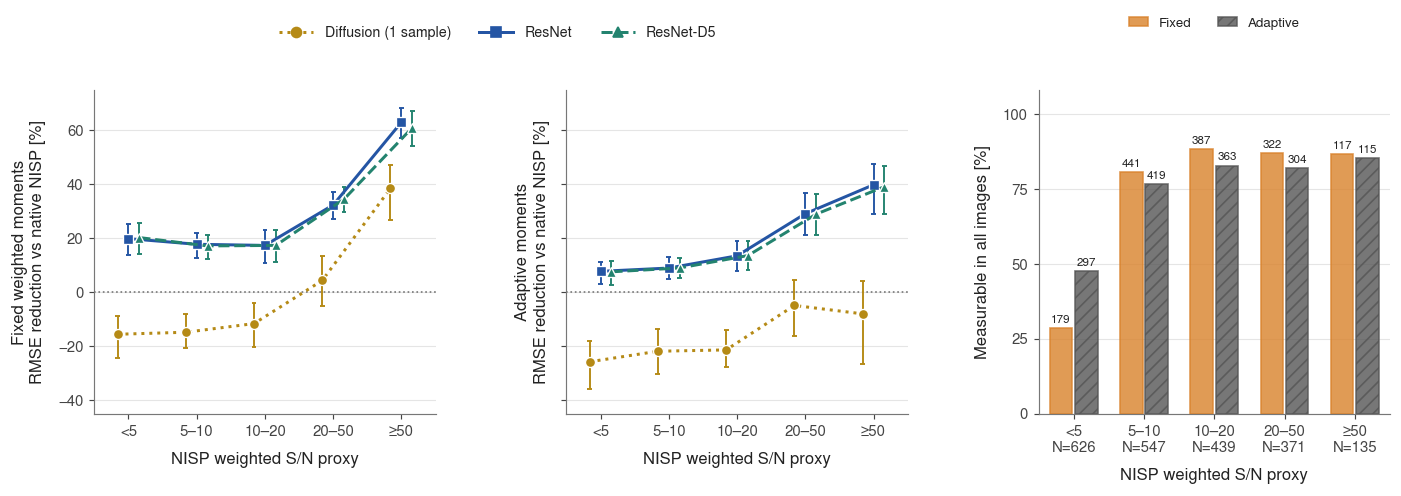

Exported: fig08_shape_dependence_v04.pdf, fig08_shape_dependence_v04.svg, fig08_shape_dependence_v04.png


[PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig08_shape_dependence_v04.pdf'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig08_shape_dependence_v04.svg'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig08_shape_dependence_v04.png')]

In [2]:
fig,axes=plt.subplots(1,3,figsize=(11.8,4.15),gridspec_kw={'width_ratios':[1,1,1.03]})
x=np.arange(5)
markers=MARKERS
offsets={'diffusion':-.16,'legacy':0.,'direct5':.16}
styles={'diffusion':':','legacy':'-','direct5':'--'}
for ax,case,title in zip(axes[:2],['fixed','adaptive'],['Fixed weighted moments','Adaptive moments']):
    rows=b['summaries'][case]
    ax.axhline(0,color='#777777',lw=1,ls=':',zorder=1)
    for name in shown:
        gain=np.array([r['native_comparison'][name]['reduction_percent'][0] for r in rows])
        ci=np.array([r['native_comparison'][name]['ci95_percent'][0] for r in rows])
        positions=x+offsets[name]
        ax.plot(positions,gain,marker=markers[name],ls=styles[name],lw=1.8,
                ms=6,mfc=COLORS[name],mec='white',mew=.8,color=COLORS[name],label=labels[name],zorder=3)
        # Intervals are drawn independently; no symmetric-error assumption.
        ax.vlines(positions,ci[:,0],ci[:,1],color=COLORS[name],lw=1.15,zorder=2)
        ax.hlines(ci[:,0],positions-.035,positions+.035,color=COLORS[name],lw=1.15)
        ax.hlines(ci[:,1],positions-.035,positions+.035,color=COLORS[name],lw=1.15)
    ax.set_ylim(-45,75);ax.set_yticks([-40,-20,0,20,40,60])
    ax.set_ylabel(f'{title}\nRMSE reduction vs native NISP [%]',labelpad=7)
    ax.set_xticks(x,b['bins']['labels'])
    ax.grid(axis='y',alpha=.14)
axes[1].tick_params(labelleft=False)
ax=axes[2]
for case,offset,color,text_color,label in [('fixed',-.18,ESTIMATOR_COLORS['fixed'],INK,'Fixed'),
                                           ('adaptive',.18,ESTIMATOR_COLORS['adaptive'],INK,'Adaptive')]:
    rows=b['summaries'][case]
    total=np.array([r['objects'] for r in rows]);common=np.array([r['common_successes'] for r in rows])
    assert int(total.sum())==b['objects']
    assert int(common.sum())==shapes['summaries'][case]['common_successes']
    fraction=100*common/total
    ax.bar(x+offset,fraction,width=.32,color=color,alpha=.8,edgecolor=color,
           hatch='///' if case=='adaptive' else None,label=label,zorder=2)
    for pos,height,count in zip(x+offset,fraction,common):
        ax.text(pos,height+1.2,str(count),ha='center',va='bottom',fontsize=7,color=text_color)
ax.set_ylim(0,108);ax.set_yticks([0,25,50,75,100])
ax.set_ylabel('Measurable in all images [%]',labelpad=7)
ax.set_xticks(x,[f'{label}\nN={r["objects"]}' for label,r in zip(b['bins']['labels'],rows)])
ax.grid(axis='y',alpha=.14)
ax.legend(loc='lower center',ncol=2,frameon=False,fontsize=8,
          bbox_to_anchor=(.5,1.15),handlelength=1.4)
for ax in axes:
    finish_axes(ax,grid='y')
    ax.set_xlim(-.5,4.5)
    ax.set_xlabel('NISP weighted S/N proxy',labelpad=8)
handles=[Line2D([],[],color=COLORS[m],marker=markers[m],ls=styles[m],lw=1.8,ms=6,label=labels[m]) for m in shown]
fig.legend(handles=handles,loc='upper center',bbox_to_anchor=(.36,1.015),
           ncol=3,frameon=False,fontsize=8.5,handlelength=2.4)
fig.subplots_adjust(left=.075,right=.99,top=.86,bottom=.21,wspace=.38)
plt.show()
export(fig,f'fig08_shape_dependence_{VERSION}','08_shape_dependence.ipynb',
       [path,ROOT/b['arrays_path'],shapes_path,ROOT/shapes['arrays_path']],
       dict(methods=shown,estimators=['fixed','adaptive'],bins=b['bins'],
            population=b['population'],metric=b['metric'],uncertainty=b['uncertainty'],
            axis_limits_percent=[-45,75],horizontal_offsets=offsets,
            panel_titles=False,estimator_names='y-axis labels',
            coverage='Common successful images: JWST, native NISP, bilinear, bicubic, diffusion, diffusion mean3, ResNet, ResNet-D5; denominator all attempted objects in each bin.'),
       status='Current-model Figure 8: S/N dependence and common measurement coverage')


## Working caption

Observed-shape recovery as a function of input NISP weighted S/N. Left and middle:
percentage reduction in ellipticity-component RMSE relative to native NISP for
fixed weighted and adaptive moments, respectively. Positive values indicate
lower error against observed JWST F115W. Each estimator/bin uses the same galaxies
measurable in JWST, native NISP and all six cached methods. Points are offset
within each categorical bin for visibility; connecting lines guide the eye.
Whiskers are conditional 95% intervals from 2,000 paired spatial-block resamples.
They are marginal intervals, not a simultaneous test of a trend across bins.
Right: the fraction of all attempted galaxies in each bin entering these
comparisons; numbers above bars give common successes and $N$ below each bin
gives its total count. Solid amber bars denote fixed moments; hatched charcoal
bars denote adaptive moments. The fixed/adaptive totals are 1,446/1,498 successes out of
2,118 attempted validation fields. The predefined bins are $(-\infty,5)$,
$[5,10)$, $[10,20)$, $[20,50)$ and $[50,\infty)$.

The S/N proxy is native signed Gaussian-weighted flux divided by quadrature
weighted pixel RMS, ignoring correlated noise. It is not a calibrated detection
significance. Fixed and adaptive moments measure different weighted shapes and
have different successful samples. These observed cross-band comparisons include
PSF and pixel-sampling differences and do not establish calibrated shear recovery.


## Numerical comparisons, including the interpolation and mean-image checks

In [3]:
records=[]
for case,rows in b['summaries'].items():
    for row in rows:
        for name in b['methods']:
            rec=row['native_comparison'][name]
            records.append(dict(estimator=case,snr_bin=row['label'],method=labels[name],
                attempted=row['objects'],common=row['common_successes'],spatial_blocks=row['spatial_blocks'],
                shape_rmse=rec['rmse'][0],gain_percent=rec['reduction_percent'][0],ci95=rec['ci95_percent'][0]))
display(pd.DataFrame(records))


,estimator,snr_bin,method,attempted,common,spatial_blocks,shape_rmse,gain_percent,ci95
0,fixed,<5,Native NISP,626,179,17,0.361892,0.000000,"[0.0, 0.0]"
1,fixed,<5,Bilinear,626,179,17,0.334962,7.441602,"[5.628157452381618, 8.835907519577223]"
2,fixed,<5,Bicubic,626,179,17,0.362426,-0.147535,"[-1.5648184971167172, 1.068508112379344]"
3,fixed,<5,Diffusion (1 sample),626,179,17,0.418270,-15.578549,"[-24.384398424294755, -8.759238340978126]"
4,fixed,<5,Diffusion (mean of 3),626,179,17,0.342128,5.461467,"[-2.4301197939916426, 12.930461397199238]"
...,...,...,...,...,...,...,...,...,...
65,adaptive,≥50,Bicubic,135,115,17,0.105898,-2.491217,"[-3.5975507804277114, -1.6267749177022617]"
66,adaptive,≥50,Diffusion (1 sample),135,115,17,0.111593,-8.003690,"[-26.63063645662723, 4.108764511858395]"
67,adaptive,≥50,Diffusion (mean of 3),135,115,17,0.094114,8.913283,"[-6.21878291358087, 21.017525867564895]"
68,adaptive,≥50,ResNet,135,115,17,0.062169,39.830668,"[29.05805568853439, 47.579640598905875]"


## Full-denominator measurement success and a common sample across estimators

In [4]:
coverage=[];matched=[]
for case,rows in b['summaries'].items():
    for row,joint in zip(rows,b['cross_estimator_common'][case]):
        coverage.append(dict(estimator=case,snr_bin=row['label'],attempted=row['objects'],
                             common=row['common_successes'],**{labels[k]:v for k,v in row['success_counts'].items()}))
        for name in shown:
            rec=joint['native_comparison'][name]
            matched.append(dict(estimator=case,snr_bin=row['label'],objects=joint['objects'],method=labels[name],
                                gain_percent=rec['reduction_percent'][0],ci95=rec['ci95_percent'][0]))
display(pd.DataFrame(coverage))
display(pd.DataFrame(matched))


,estimator,snr_bin,attempted,common,JWST,Native NISP,Bilinear,Bicubic,Diffusion (1 sample),Diffusion (mean of 3),ResNet,ResNet-D5
0,fixed,<5,626,179,370,357,360,325,344,418,479,479
1,fixed,5–10,547,441,466,505,475,471,463,478,481,481
2,fixed,10–20,439,387,387,406,387,387,387,387,387,387
3,fixed,20–50,371,322,322,345,322,322,322,322,322,322
4,fixed,≥50,135,117,117,128,117,117,117,117,117,117
5,adaptive,<5,626,297,501,373,398,404,417,455,471,473
6,adaptive,5–10,547,419,464,467,441,448,459,465,468,468
7,adaptive,10–20,439,363,377,385,368,368,375,376,375,375
8,adaptive,20–50,371,304,310,333,309,310,312,312,312,313
9,adaptive,≥50,135,115,115,127,116,116,115,116,116,116


,estimator,snr_bin,objects,method,gain_percent,ci95
0,fixed,<5,129,Diffusion (1 sample),-12.432727,"[-24.772934616974947, -3.947518368221877]"
1,fixed,<5,129,ResNet,24.169033,"[17.05477411860586, 29.98190244232085]"
2,fixed,<5,129,ResNet-D5,24.107005,"[16.447065576318035, 30.508420590767834]"
3,fixed,5–10,386,Diffusion (1 sample),-13.215672,"[-18.872256450237373, -6.598987244461451]"
4,fixed,5–10,386,ResNet,19.552794,"[14.186060661335684, 23.956569914440113]"
5,fixed,5–10,386,ResNet-D5,18.953099,"[13.49522925904889, 23.38268893135613]"
6,fixed,10–20,363,Diffusion (1 sample),-14.200314,"[-22.570801231675112, -5.8958771499531695]"
7,fixed,10–20,363,ResNet,20.428738,"[17.16530606410239, 23.814044451092876]"
8,fixed,10–20,363,ResNet-D5,20.347624,"[16.305755026967866, 24.32359159871143]"
9,fixed,20–50,304,Diffusion (1 sample),4.854441,"[-3.218397978577615, 13.313943444023755]"


## Interpretation

The same per-object measurements underlie Figures 7 and 8: recombining squared
bin RMSE values with their common-object counts exactly recovers Figure 7's
aggregate RMSE. Percent gains themselves should not be averaged across bins.
No bins were adjusted in response to the model results.

The low-S/N error comparison represents only the galaxies with measurable shapes;
the coverage panel makes that selection explicit. A positive conditional gain
is not evidence that all faint sources become useful shape measurements.
S/N and native ellipticity share input pixels, while size, brightness, crowding
and redshift can also vary between bins; this is a descriptive dependence,
not a causal effect of changing S/N. The mean-of-three image and interpolation
controls remain in the tables. Independent training seeds or continuation
checkpoints are not substituted for the fixed model choices in Figures 6 and 7.
